LOGISTIC REGRESSION

1. Data Exploration:        
a. Load the dataset and perform exploratory data analysis (EDA).        
b. Examine the features, their types, and summary statistics.       
c. Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.        
Analyze any patterns or correlations observed in the data.      


In [263]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [264]:
df=pd.read_csv("diabetes.csv")

In [265]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [266]:
df.shape

(768, 9)

In [267]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [268]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [269]:
df.duplicated().sum()

np.int64(0)

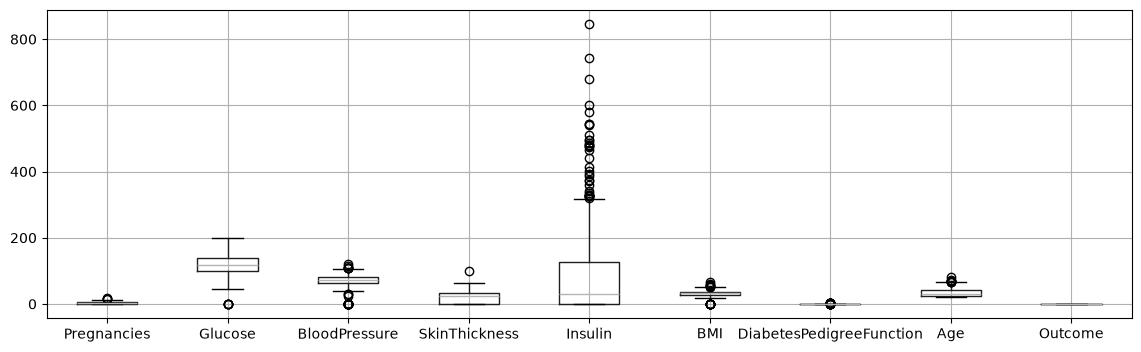

In [270]:
plt.figure(figsize=(14,4))
df.boxplot()
plt.show()

In [271]:
#### outlier capping
def outlier_capping(df,column):
    Q1= df[column].quantile(0.25)
    Q3= df[column].quantile(0.75)
    IQR= Q3-Q1
    lower_extreme= Q1-1.5*IQR
    upper_extreme= Q3+1.5*IQR
    df[column]= df[column].apply(lambda x: lower_extreme if x< lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(include=['int','float']).columns:
    outlier_capping(df,col)

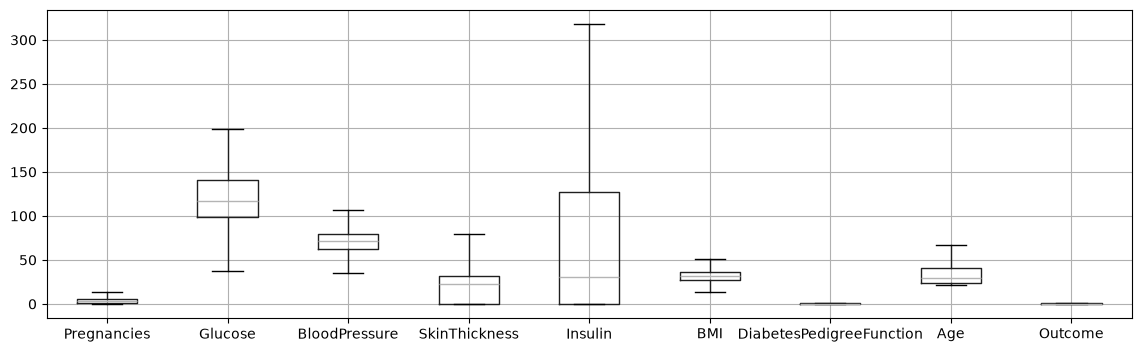

In [272]:
plt.figure(figsize=(14,4))
df.boxplot()
plt.show()

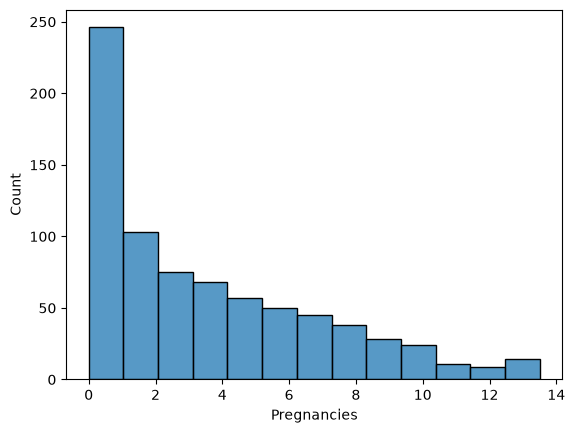

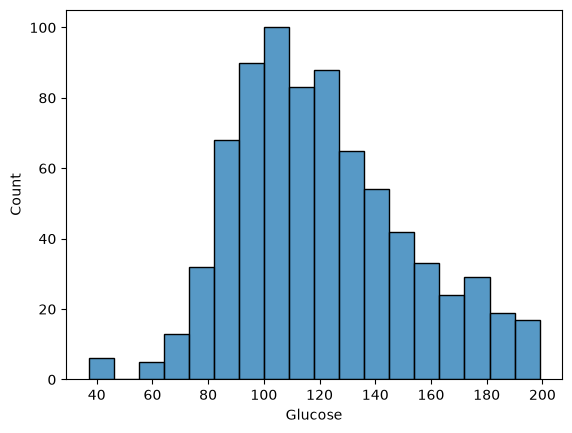

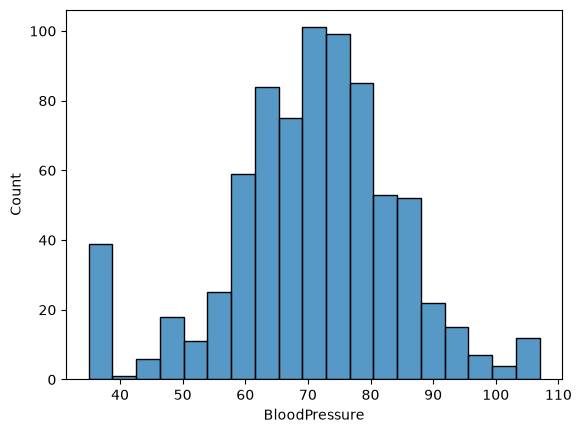

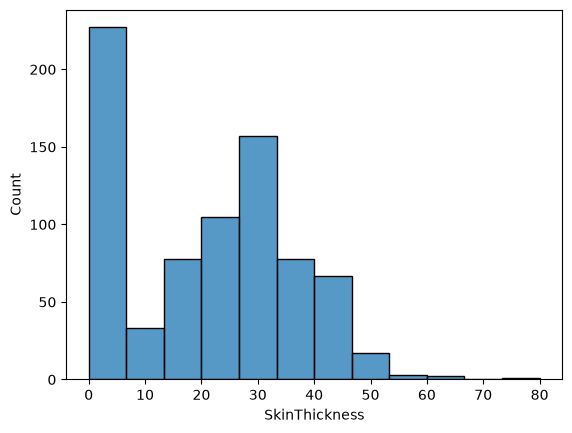

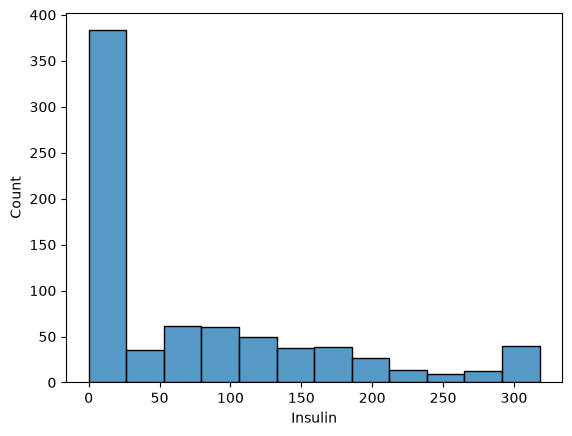

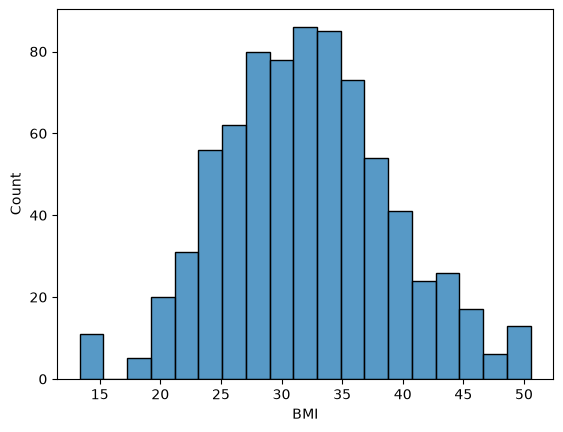

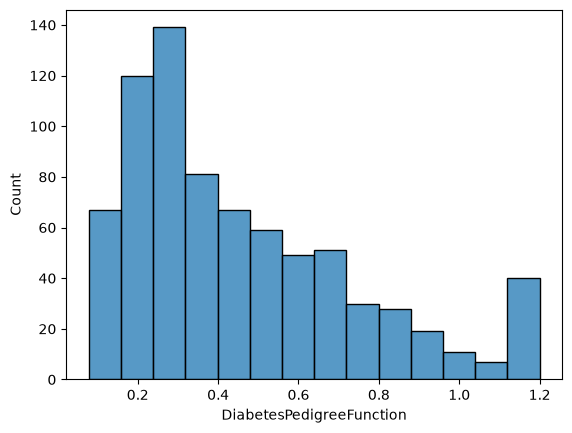

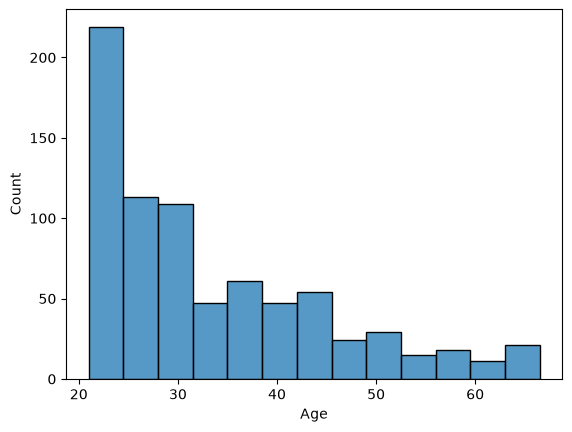

In [273]:
for i in df.columns[:-1]:    
    sns.histplot(df[i])
    plt.show()

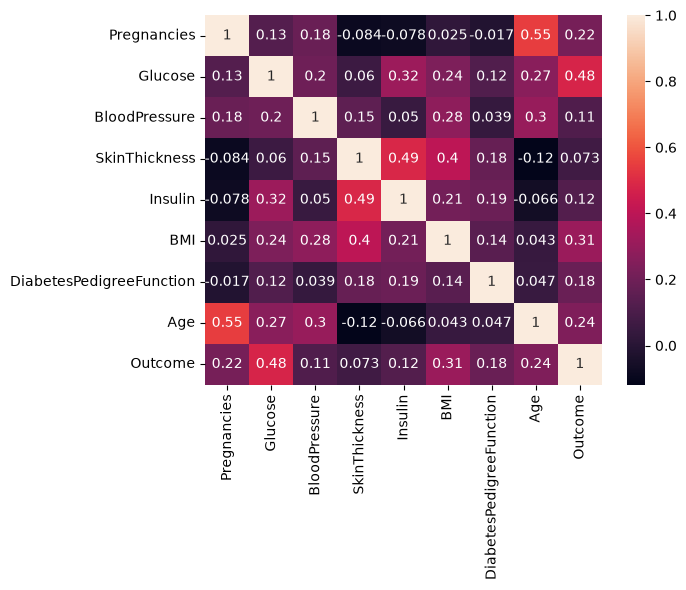

In [274]:
corr=df.corr()
sns.heatmap(corr,annot=True)
plt.show()

2. Data Preprocessing:      
a. Handle missing values (e.g., imputation).        
b. Encode categorical variables.        


In [275]:
cols_with_zeros=['SkinThickness','Insulin']

In [276]:
zeros_count=(df[cols_with_zeros]==0).sum()
zeros_count

SkinThickness    227
Insulin          374
dtype: int64

In [277]:
df[cols_with_zeros]=df[cols_with_zeros].replace(0, np.nan)

In [278]:
#Impute with median
for col in cols_with_zeros:
    df[col]=df[col].fillna(df[col].median())

In [279]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [280]:
#since there are no categorical variables there is no need for Encode categorical variables step.

3. Model Building:      
a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn).      
b. Train the model using the training data.


In [281]:
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

In [282]:
features=df.drop(columns=['Outcome'])
target=df['Outcome']

In [283]:
features.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.0,125.0,33.6,0.627,50.0
1,1.0,85.0,66.0,29.0,125.0,26.6,0.351,31.0
2,8.0,183.0,64.0,29.0,125.0,23.3,0.672,32.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0
4,0.0,137.0,40.0,35.0,168.0,43.1,1.200,33.0


In [284]:
f_clas=f_classif(features,target)

In [285]:
pd.Series(f_clas[0],index=features.columns)

Pregnancies                  39.106100
Glucose                     228.278996
BloodPressure                 9.961146
SkinThickness                37.209652
Insulin                      44.518877
BMI                          81.287147
DiabetesPedigreeFunction     27.135876
Age                          47.944757
dtype: float64

In [286]:
x_train,x_test,y_train,y_test=train_test_split(features,target,test_size=0.2,random_state=42)

In [287]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((614, 8), (154, 8), (614,), (154,))

In [288]:
std_sca=StandardScaler()

In [289]:
x_train.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='str')

In [290]:
cols=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']

In [291]:
x_train[cols]=std_sca.fit_transform(x_train[cols])
x_test[cols]=std_sca.transform(x_test[cols])

In [292]:
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
60,-0.528662,-1.197609,-2.578159,0.034298,-0.147118,-2.675470,-0.531720,-1.046838
618,1.606853,-0.295149,0.808146,-0.560583,-0.147118,-0.553023,2.644625,1.513601
346,-0.833735,0.575081,-1.785619,-1.155463,-0.843836,-0.481560,0.709040,-0.958547
294,-1.138809,1.284156,-1.497423,0.034298,-0.147118,-1.453455,-0.708971,2.837966
231,0.691632,0.413927,0.664048,0.986106,3.056538,2.019641,-0.765691,1.160437


In [293]:
#Train the model
log_reg_model=LogisticRegression()
log_reg_model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [294]:
y_pred=log_reg_model.predict(x_test)
y_pred_proba=log_reg_model.predict_proba(x_test)[:,1]

4. Model Evaluation:        
a. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.
Visualize the ROC curve.


In [295]:
from sklearn.metrics import classification_report,roc_auc_score,roc_curve

In [296]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.81      0.81        99
           1       0.65      0.65      0.65        55

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



In [297]:
roc_auc=roc_auc_score(y_test,y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

ROC-AUC Score: 0.8193


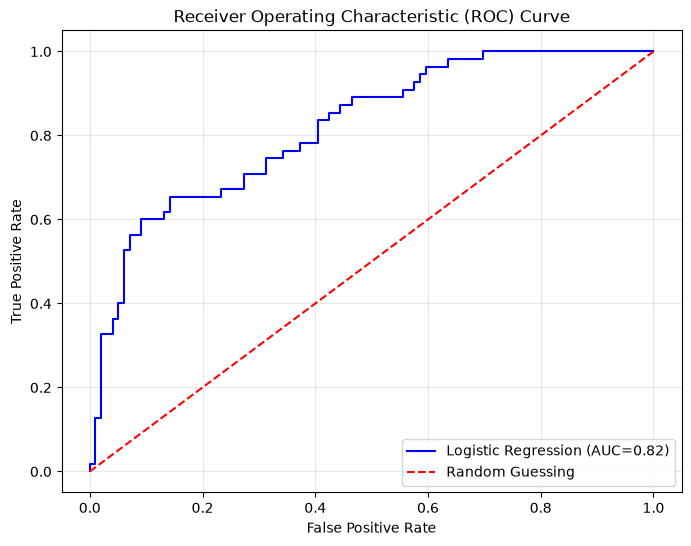

In [298]:
fpr,tpr,thresholds=roc_curve(y_test,y_pred_proba)

plt.figure(figsize=(8,6))
plt.plot(fpr,tpr,color='blue',label=f'Logistic Regression (AUC={roc_auc:.2f})')
plt.plot([0,1],[0,1],color='red',linestyle='--',label='Random Guessing')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)

# Show the plot
plt.show()

5. Interpretation:      
a. Interpret the coefficients of the logistic regression model.
b. Discuss the significance of features in predicting the target variable (survival probability in this case).


In [299]:
coefficients=pd.DataFrame({
    'Feature':features.columns,
    'Coefficient':log_reg_model.coef_[0],
})

print(coefficients.to_string(index=False))

                 Feature  Coefficient
             Pregnancies     0.202458
                 Glucose     1.030403
           BloodPressure    -0.242286
           SkinThickness     0.069390
                 Insulin    -0.061256
                     BMI     0.721636
DiabetesPedigreeFunction     0.261677
                     Age     0.462865


In [300]:
import pickle

In [301]:
# Save the trained model
with open('logistic_model.pkl','wb') as file:
    pickle.dump(log_reg_model, file)

# Save the scaler
with open('scaler.pkl','wb') as file:
    pickle.dump(std_sca, file)

6. Deployment with Streamlit:       
In this task, you will deploy your logistic regression model using Streamlit. The deployment can be done locally or online via Streamlit Share. Your task includes creating a Streamlit app in Python that involves loading your trained model and setting up user inputs for predictions. 


In [302]:
import streamlit as st

In [303]:
st.title("Diabetes Prediction App")
st.write("Enter the patient's medical details below to predict the likelihood of diabetes based on our Logistic Regression model.")

st.markdown("---")

# 3. Set up User Inputs (Sliders and Number Inputs)
col1,col2=st.columns(2)

with col1:
    pregnancies=st.number_input("Pregnancies", min_value=0, max_value=20, value=1)
    glucose=st.slider("Glucose Level", min_value=0, max_value=250, value=120)
    blood_pressure=st.slider("Blood Pressure (mm Hg)", min_value=0, max_value=150, value=70)
    skin_thickness=st.slider("Skin Thickness (mm)", min_value=0, max_value=100, value=20)

with col2:
    insulin=st.slider("Insulin Level (IU/mL)", min_value=0, max_value=900, value=79)
    bmi=st.number_input("BMI (Body Mass Index)", min_value=0.0, max_value=70.0, value=25.0)
    dpf=st.number_input("Diabetes Pedigree Function", min_value=0.0, max_value=3.0, value=0.5)
    age=st.slider("Age", min_value=1, max_value=120, value=33)

st.markdown("---")

# 4. Predict Button
if st.button("Predict Diabetes Risk"):
    # Organize inputs into a numpy array
    input_data=np.array([[pregnancies, glucose, blood_pressure, skin_thickness, insulin, bmi, dpf, age]])
    
    # Scale the input using the loaded scaler
    input_scaled=std_sca.transform(input_data)
    
    # Get prediction and probabilities
    prediction=log_reg_model.predict(input_scaled)
    probability=log_reg_model.predict_proba(input_scaled)[0][1] 
    
    # Display the results
    st.subheader("Prediction Results:")
    if prediction[0]==1:
        st.error(f"**High Risk:** The model predicts a positive diagnosis for diabetes.")
    else:
        st.success(f"**Low Risk:** The model predicts a negative diagnosis for diabetes.")
        
    st.write(f"**Probability of Diabetes:** {probability * 100:.1f}%")

2026-09-12 21:26:10.015 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-12 21:26:10.016 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-12 21:26:10.016 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-12 21:26:10.017 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-12 21:26:10.018 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-12 21:26:10.018 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-12 21:26:10.019 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-12 21:26:10.019 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

Interview Questions:        
1. What is the difference between precision and recall?


In [304]:
print("Precision measures the quality of your predictions like how many of the predicted positives\n were actually positive, while recall measures quantity like how many of the actual \nreal-world positives your model successfully found.")

Precision measures the quality of your predictions like how many of the predicted positives
 were actually positive, while recall measures quantity like how many of the actual 
real-world positives your model successfully found.


2. What is cross-validation, and why is it important in binary classification?

In [306]:
print("Cross-validation evaluates the model across multiple data splits to ensure its\n performance is robust.It ensures both classes are proportionally \nrepresented in every test split, preventing the model from becoming biased toward the majority class.")

Cross-validation evaluates the model across multiple data splits to ensure its
 performance is robust.It ensures both classes are proportionally 
represented in every test split, preventing the model from becoming biased toward the majority class.
